# Import all packages

In [28]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

# using CairoMakie
# using PairPlots
# using DataFrames

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

In [29]:
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\FunctionsInferenceScallable.jl")

CompRepUtil_Entro_OEDmc2 (generic function with 1 method)

# Define Priors

In [30]:
priorTheta, priotY0, sampsTh, sampsY0 = genPriorSamps(8000);
bounds, boundY0 = genThetaBounds();


In [33]:
priorInfer =  Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try1.csv", DataFrame))

8000×17 Matrix{Float64}:
 47.3787  51.23  0.00155966  0.0145029  …  531.554   1924.36   0.0859339
 43.4375  51.23  0.00104747  0.0147182     262.31     711.768  0.0681909
 39.4956  51.23  0.00578949  0.0152421     493.286    417.298  0.196644
 46.7641  51.23  0.00241599  0.0178411     196.229   4292.87   0.181209
 37.6573  51.23  0.00487215  0.0137971     604.984   4035.78   0.180783
 38.3438  51.23  0.00379106  0.0136018  …  579.193   4265.48   0.758058
 48.3472  51.23  0.00170405  0.0178613     415.719   3403.71   0.248787
 29.9887  51.23  0.00677593  0.0120929     509.082   3611.95   0.646214
 28.2813  51.23  0.00594078  0.0121592      71.7865  1608.42   0.480568
 51.2978  51.23  0.00362439  0.0182823     307.527   1326.18   0.0558947
  ⋮                                     ⋱               ⋮      
 35.4757  51.23  0.00365653  0.0139167     180.175   3378.62   0.252308
 32.4388  51.23  0.00422033  0.012934      209.035   3118.73   0.458853
 32.5585  51.23  0.00332311  0.0130423     2

# Compute Objective Function for All Available Experiments

In [34]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:14];
global sampsY0 = priorInfer[:,15:end];

pyrs = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40]
# pyrs = [0.6, 0.8, 1.6, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40] # At each iteration we remove past experiments

objs = zeros(length(pyrs))

for i in 1:length(pyrs)
    objs[i] = CompRepUtil_Entro_OEDmc2([pyrs[i]])
end

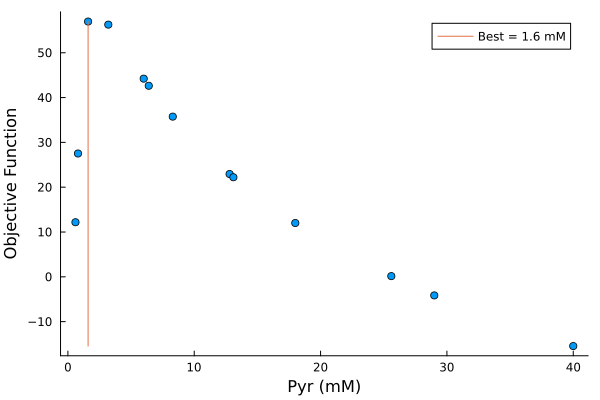

In [35]:
bstIn = findfirst(objs .== maximum(objs))

scatter(pyrs, objs, label = "", grid = false, ylabel = "Objective Function", xlabel = "Pyr (mM)")
plot!([pyrs[bstIn], pyrs[bstIn]], [minimum(objs), objs[bstIn]], label = "Best = "*string(pyrs[bstIn])*" mM")

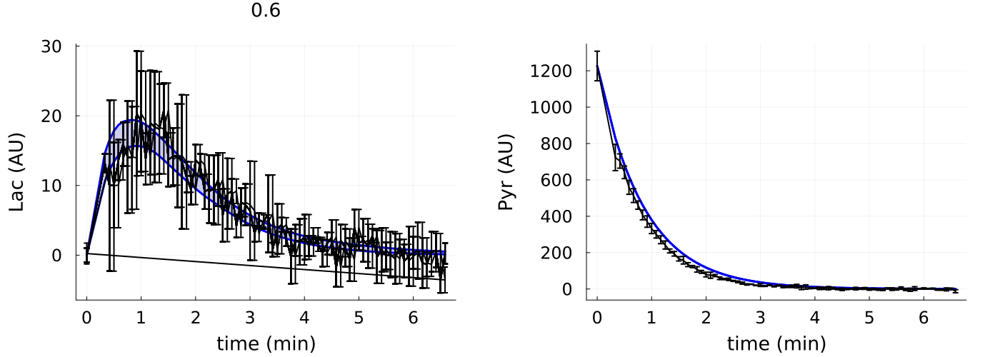

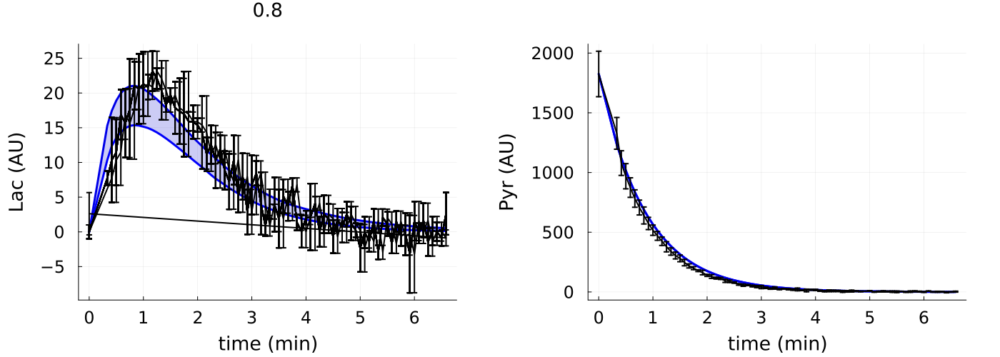

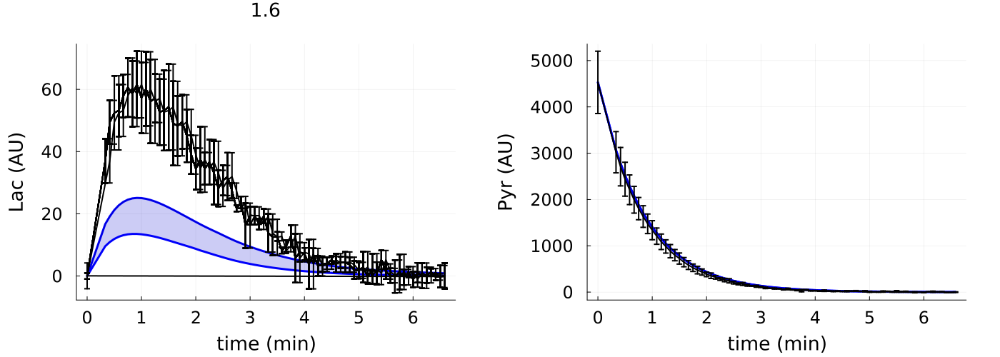

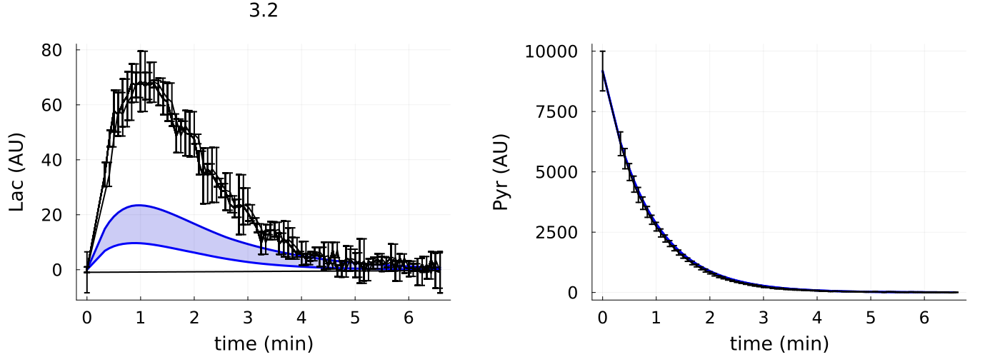

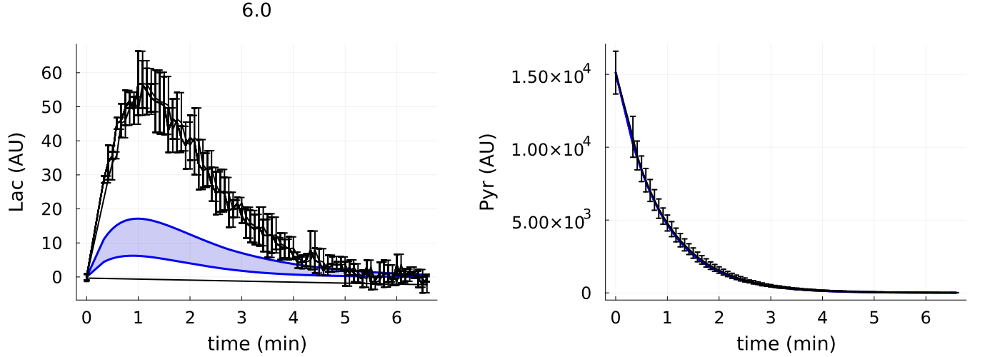

...

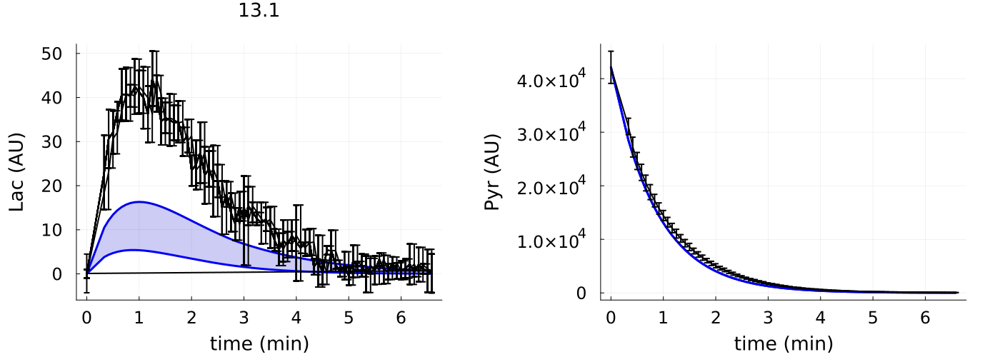

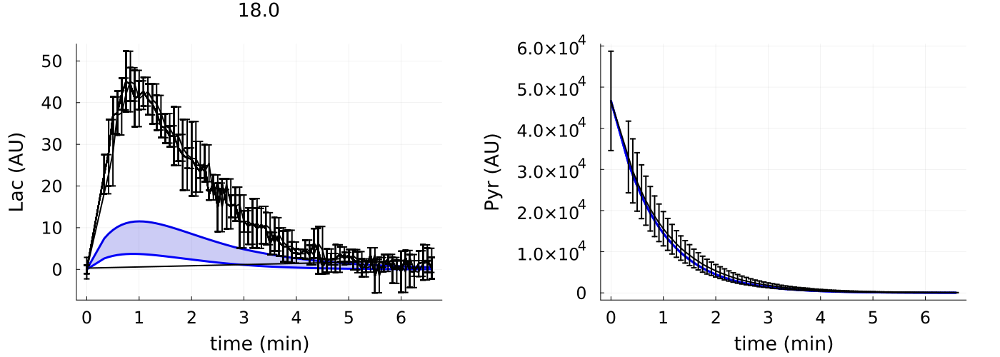

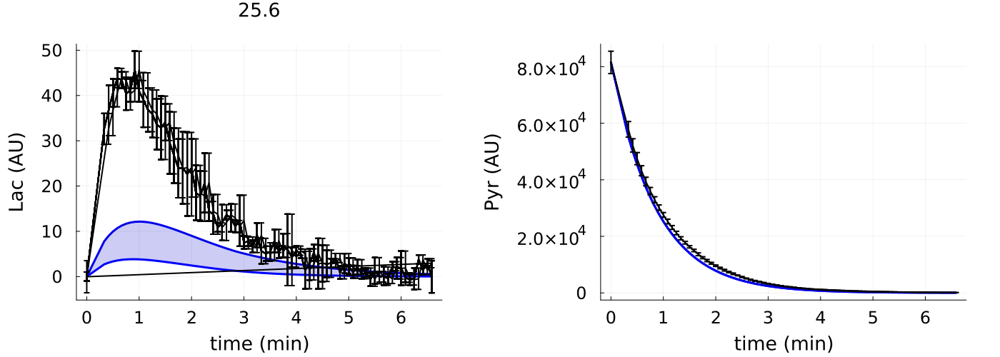

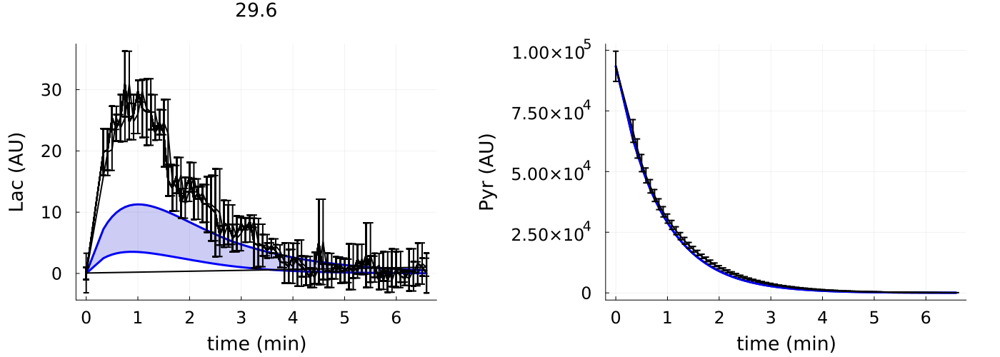

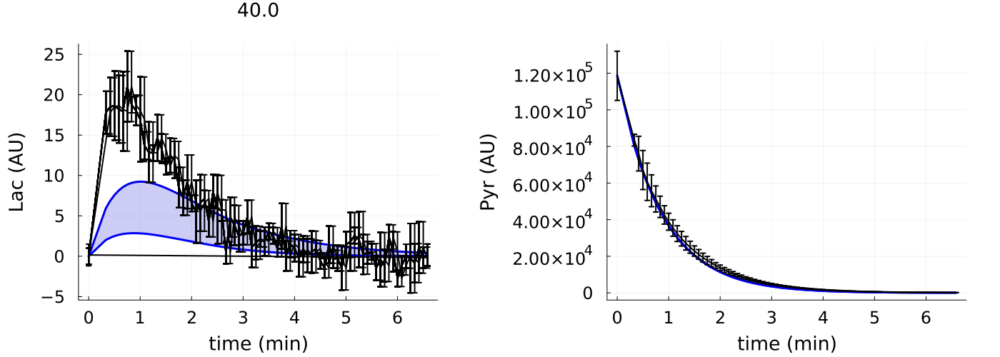

In [40]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths2 = [mainpath*"3Mil_0-6mMPyr_Dat.csv", mainpath*"3Mil_0-8mMPyr_Dat.csv", mainpath*"3Mil_1-6mMPyr_Dat.csv", mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_6-0mMPyr_Dat.csv", 
          mainpath*"3Mil_6-4mMPyr_Dat.csv", mainpath*"3Mil_8-3mMPyr_Dat.csv", mainpath*"3Mil_12-8mMPyr_Dat.csv", mainpath*"3Mil_13-1mMPyr_Dat.csv", mainpath*"3Mil_18-0mMPyr_Dat.csv", 
          mainpath*"3Mil_25-6mMPyr_Dat.csv", mainpath*"3Mil_29-6mMPyr_Dat.csv", mainpath*"3Mil_40-0mMPyr_Dat.csv", ];
conce2 = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29.6, 40];


Random.seed!(8987654);
global datAll = restructDatInfCompRep_RealExpDat_Scal(paths2, conce2, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])




simPriorPredictAll(200, datAll, priorInfer[:,1:14], priorInfer[:,15:end], conce2)

# Extract Experimental Data

In [42]:
pyrs[bstIn]

1.6

In [41]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_0-6mMPyr_Dat.csv", mainpath*"3Mil_"*replace(string(pyrs[bstIn]), "." => "-", count = 1)*"mMPyr_Dat.csv"];
conce = [0.6, pyrs[bstIn]];


Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat_Scal(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])

Dict{String, Any} with 16 entries:
  "Means"  => [1226.15 4528.94; 723.012 3020.78; … ; 0.320623 -4.25108; -12.129…
  "stsl"   => [77 77]
  "obSta"  => [1 2]
  "sts"    => [0 0; 20 20; … ; 390 390; 395 395]
  "obser"  => 2
  "Y0us"   => [600.0 1600.0; 0.0 0.0; … ; 0.0 0.0; 1226.15 4528.94]
  "ts"     => [1.0e-20 1.0e-20; 1.0 1.0; … ; 394.0 394.0; 395.0 395.0]
  "itp"    => [0.0, 0.0]
  "ScFms"  => [17.0298 23.5882]
  "ncells" => [4 4]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [81.2187 672.75; 72.3012 445.178; … ; 4.42203 5.21821; 8.64195 6.…
  "m"      => 2
  "nmCls"  => [3.0e6 3.0e6]
  "nts"    => [395 395]

# Simulate Experiment Prior Prediction
CAREFUL!!! Simulations take a minute or more if you take all the samples!

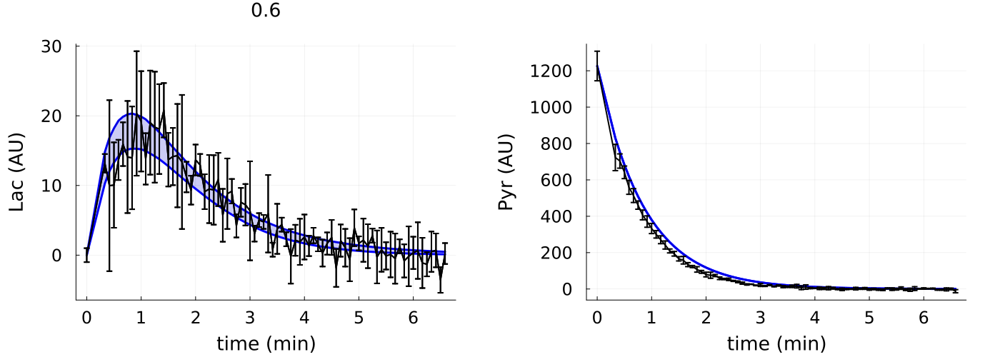

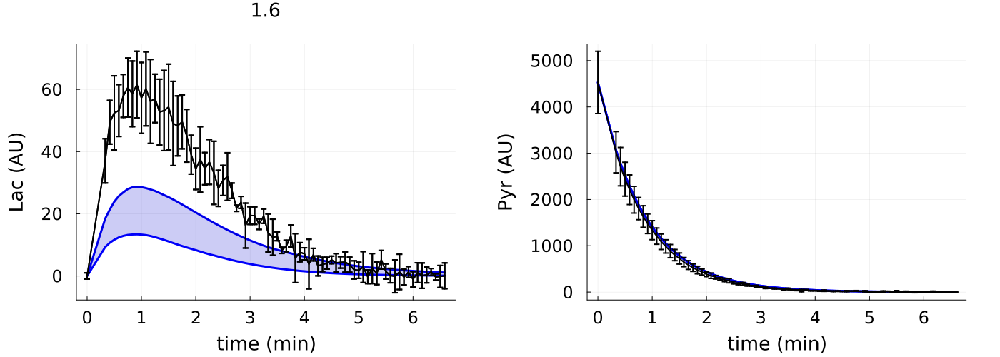

In [43]:
simPriorPredictAll(2000, dat, priorInfer[:,1:14], priorInfer[:,15:end], conce)

# MLE to obtain a good first guess for inference

In [44]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 3e6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE2(p)

4.815427599818998e15

In [45]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE2; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:13], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*10, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.56 secs, 86 evals, 46 steps, improv/step: 0.478 (last = 0.4783), fitness=959.467783101
1.06 secs, 179 evals, 112 steps, improv/step: 0.473 (last = 0.4697), fitness=888.886345748
1.58 secs, 275 evals, 190 steps, improv/step: 0.426 (last = 0.3590), fitness=888.886345748
2.08 secs, 369 evals, 270 steps, improv/step: 0.426 (last = 0.4250), fitness=861.130526291
2.59 secs, 466 evals, 362 steps, improv/step: 0.401 (last = 0.3261), fitness=861.130526291
3.09 secs, 559 evals, 452 steps, improv/step: 0.378 (last = 0.2889), fitness=540.198777926
3.59 secs, 653 evals, 545 steps, improv/step: 0.354 (last = 0.2366), fitness=540.198777926
4.10 secs, 750 evals, 638 steps, improv/step: 0.329 (last = 0.1828), fitness=540.198777926
4.61 secs, 841 evals, 725 steps, improv/step: 0.317 (last = 0.2299), f

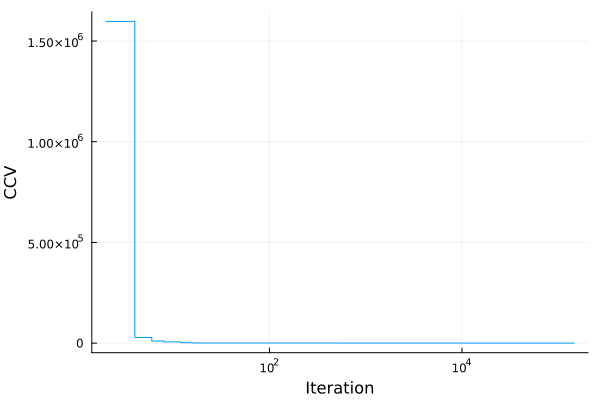

┌ Warning: Attempting to store var"#213#214".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [46]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

# Extract Parameter Vector
parfitT = zeros(16, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind];

# Save Data
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMTRRCmp_Exper_Iter1.jld2", "FitsT",FitsT)
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter1.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

In [47]:
# Load Data
ppT = JLD2.load("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter1.jld2")["resMMat"][:,1]

16-element Vector{Float64}:
   56.659858878337545
   51.23
    5.9764558645412596e-5
    0.014586678951754107
    1.4525948272228068e-7
    0.19097725711153982
    1.999997985383421
    0.6605431970139043
    0.018030306840311865
    9.999937640311973e-6
    1.999997614603514
    2.4596995245875856e-10
    3.0e6
  193.68160189637962
 8226.635406127996
    1.1679999668747838

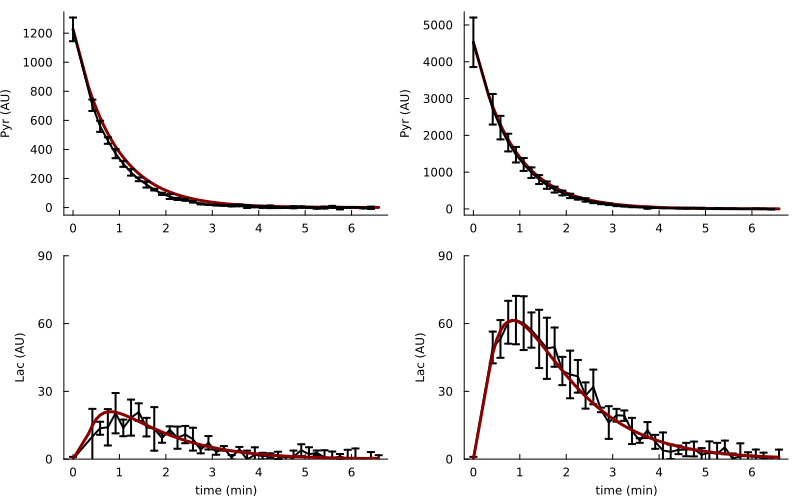

In [48]:
pst = Array{Any}(undef, length(conce))
i = 1
for i in 1:length(conce)
     tsC2 = dat["sts"][:,i];
     if i == 3
          tsC2 = dat["sts"][1:end-1,3];
     end
     ts = 0:tsC2[end];
     ivss = [round(conce[i], digits = 1)*1000, 0, 0, ppT[14], ppT[15], ppT[16], 0, 0, 0, 0, 0, round(conce[i], digits = 1)*1000, 0, round(conce[i], digits = 1)*1000*(dat["ScFms"][i]*0.12)];;
     samps = convert.(Int, tsC2);

     SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(ppT[1:13], dat["ScFms"][i], 0), ivss, samps);

     pps = plot(dat["sts"][1:2:end,i]./60, dat["Means"][1:2:end,i,2], yerror = dat["Erros"][1:2:end,i,2], linewidth = 2, colour = "black", label = "",
               margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18),
               xlabel = "time (min)", ylabel = "Lac (AU)", size = (800,500))

          plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4", label = "", grid = false, ylim=(0,90))


     ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4", label = "", grid = false,
          margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18))
     plot!(dat["sts"][1:2:end-1,i]./60, dat["Means"][1:2:end-1,i,1], yerror = dat["Erros"][1:2:end-1,i,1], linewidth = 2, colour = "black", label = "", ylabel = "Pyr (AU)")

     pst[i] = plot(ps, pps, layout=(2,1))
end

plot(pst...)

## Compute structure for Stan's initial guess

In [49]:
jj = vcat(1, 3:12)

preTrans = zeros(14);

for i in 1:length(jj)
    
    if i == 1
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].μ)/priorTheta[jj[i]].σ;
    else
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].untruncated.μ)/priorTheta[jj[i]].untruncated.σ;
    end
    
end
kk = [14,15,16]
for i in 1:length(priotY0)
    preTrans[i+11] = (ppT[kk[i]]-priotY0[i].untruncated.μ)/priotY0[i].untruncated.σ;
end


samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict2(repeat(preTrans, 1, 10), names)

ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 2.33331
  "LDH"  => 4.00674
  "kin"  => -0.976094
  "ki"   => 1.10526
  "kunE" => -0.819697
  "kpl"  => -0.469575
  "NADH" => -1.10638
  "kup"  => -0.304691
  "T1_X" => 1.57399
  "kbp"  => 1.10526
  "kr"   => -1.0
  "NAD"  => 4.0005
  "kun"  => 0.273182
  "kbn"  => -0.709481

# Inference

In [52]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\HP_PyrLac_CmpRepresMo_Scallable2.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_Iter2_Try3", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 200, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.9;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=11;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

# StanModel = Stanmodel(name="PyrCompRepr_Iter2_Try1", model=Model, nchains =10,
#             num_samples  = 800, num_warmup = 400, printsummary=true);
# StanModel.method.save_warmup = true;
# StanModel.method.adapt.delta = 0.90;
# StanModel.method.algorithm.stepsize = 0.1;
# StanModel.method.algorithm.engine.max_depth=10;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

11

In [53]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_Iter2_Try3_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(200,200,200,200,200,200,200,200,200,200); thin=(1,1,1,1,1,1,1,1,1,1); 10000 iterations saved.

Warmup took (12607, 11151, 9504, 10542, 10787, 11903, 9860, 12681, 10578, 13019) seconds, 31 hours total
Sampling took (48853, 38473, 34696, 34608, 35520, 33406, 30699, 43012, 38418, 39317) seconds, 105 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -4.0e+02  6.5e-02  3.0e+00  -4.1e+02  -4.0e+02  -4.0e+02  2.2e+03  5.7e-03  1.0e+00
accept_stat__       0.96  6.8e-04  6.3e-02   8.2e-01      0.98      1.00  8.5e+03  2.3e-02  1.0e+00
stepsize__         0.012  8.2e-04  1.8e-03   8.6e-03     0.012     0.014  5.0e+00  1.3e-05  4.3e+13
treedepth__          8.2  1.1e-01  5.9e-01   7.0e+00       8.0       9.0  3.0e+01  8.1e-05  1.1e+00
n_leapfrog__         401  2.5e+01  1.6e+02   2.6e+02    

(0, [-428.625 0.638308 … 4312.88 0.926195; -428.625 0.0 … 4312.88 0.926195; … ; -407.938 0.984325 … 2793.97 0.698101; -409.081 0.897184 … 6900.56 0.66927;;; -422.799 0.96582 … 1138.93 0.819784; -422.799 0.0 … 1138.93 0.819784; … ; -401.92 0.970711 … 3847.6 1.01789; -401.877 0.968471 … 3707.84 1.00154;;; -429.793 0.81518 … 1299.11 0.597572; -429.793 0.0 … 1299.11 0.597572; … ; -408.358 0.956668 … 6424.96 0.634086; -402.867 0.994742 … 1747.37 0.795268;;; -432.904 0.000699194 … 8226.64 1.1692; -432.904 0.0 … 8226.64 1.1692; … ; -402.391 0.939974 … 4060.72 0.544735; -401.903 0.999561 … 2766.76 0.863424;;; -426.837 0.990593 … 3729.62 0.744639; -426.837 0.0 … 3729.62 0.744639; … ; -404.003 0.943589 … 3846.7 0.958714; -402.73 0.990616 … 2910.99 0.631715;;; -433.488 0.936843 … 461.875 0.445164; -433.488 0.0 … 461.875 0.445164; … ; -401.101 0.97216 … 3087.29 0.75889; -402.421 0.984669 … 3106.37 0.934086;;; -418.492 0.898767 … 368.891 0.875445; -418.492 0.0 … 368.891 0.875445; … ; -399.756 0.968

In [56]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PyrCompetitiveRepressionInferExpScal_Iter2_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

poster = vcat(chns[201:end, end-16:end, 1], chns[201:end, end-16:end, 2], chns[201:end, end-16:end, 3], chns[201:end, end-16:end, 4], chns[201:end, end-16:end, 5], 
              chns[201:end, end-16:end, 6], chns[201:end, end-16:end, 7], chns[201:end, end-16:end, 8], chns[201:end, end-16:end, 9], chns[201:end, end-16:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter2_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter2_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter2_Try1.csv"

In [57]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter2_Try1.csv", DataFrame))

8000×17 Matrix{Float64}:
 51.0842  51.23  3.6882e-5    0.0127673  …  347.228   3412.95   0.848161
 59.3126  51.23  7.08156e-5   0.0160709     585.944   2512.62   0.723606
 50.4575  51.23  8.57547e-5   0.013771      155.54    1238.44   1.05155
 59.4274  51.23  9.2772e-5    0.0162965     208.202   1040.38   0.955434
 52.8556  51.23  8.38459e-5   0.0129141     176.512   1365.46   0.932322
 57.8571  51.23  7.22149e-5   0.014015   …  137.962    702.931  0.724618
 59.3414  51.23  6.60347e-5   0.0184151      72.698    700.161  0.911757
 53.5074  51.23  7.84641e-5   0.0142629     831.498    722.756  0.946282
 56.8377  51.23  0.0001183    0.0137294     362.719   1001.77   1.09514
 57.8405  51.23  7.58862e-5   0.0154922     785.659   1670.32   0.991109
  ⋮                                      ⋱               ⋮      
 57.9547  51.23  9.41353e-5   0.0160193     273.485   4821.19   0.958243
 55.2586  51.23  7.57706e-5   0.0149029     169.592   3209.44   1.01351
 52.6042  51.23  0.000101265  0.01242

# Plot Posterior VS Prior

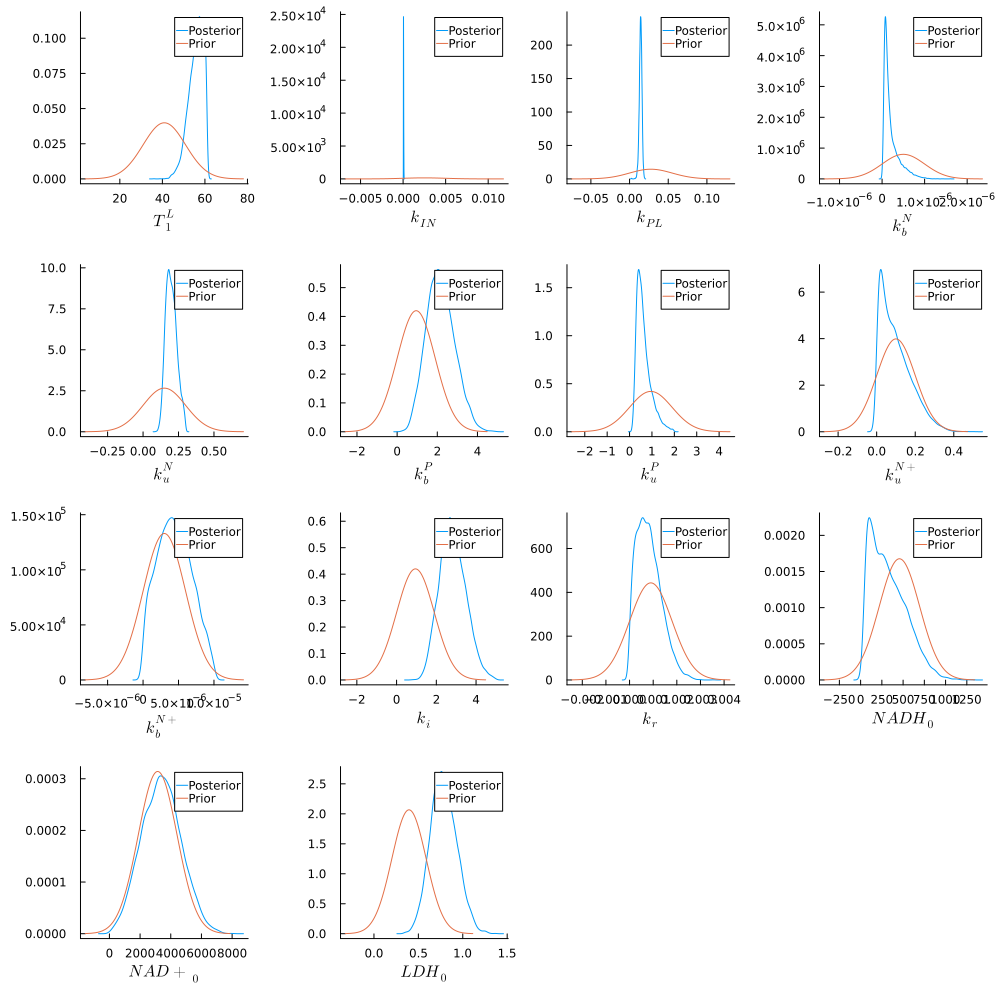

In [58]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"];

indss=vcat(1, 3:12, 15:17)
prisDis = vcat(priorTheta, priotY0)

pltsPost = Array{Any}(undef, length(indss))

for i in 1:length(indss)

    pltsPost[i] = plot(kde(poster[:,indss[i]]), label = "Posterior", xlabel = namess[i])
    try
        plot!(prisDis[indss[i]].untruncated, label = "Prior")
    catch
        plot!(prisDis[indss[i]], label = "Prior")
    end

end

plot(pltsPost..., size=(1000,1000), grid = false)

In [59]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,15:end]))))

103.26134922572723

In [60]:
[mode(poster[poster[:,11] .> 2, i]) for i in 1:17]

17-element Vector{Float64}:
   53.508
   51.23
    6.30424e-5
    0.0136622
    4.72197e-7
    0.231341
    2.62435
    0.278741
    0.0881658
    5.04722e-6
    3.01575
    0.00107497
    3.0e6
   23.5882
  713.783
 2178.47
    0.800532

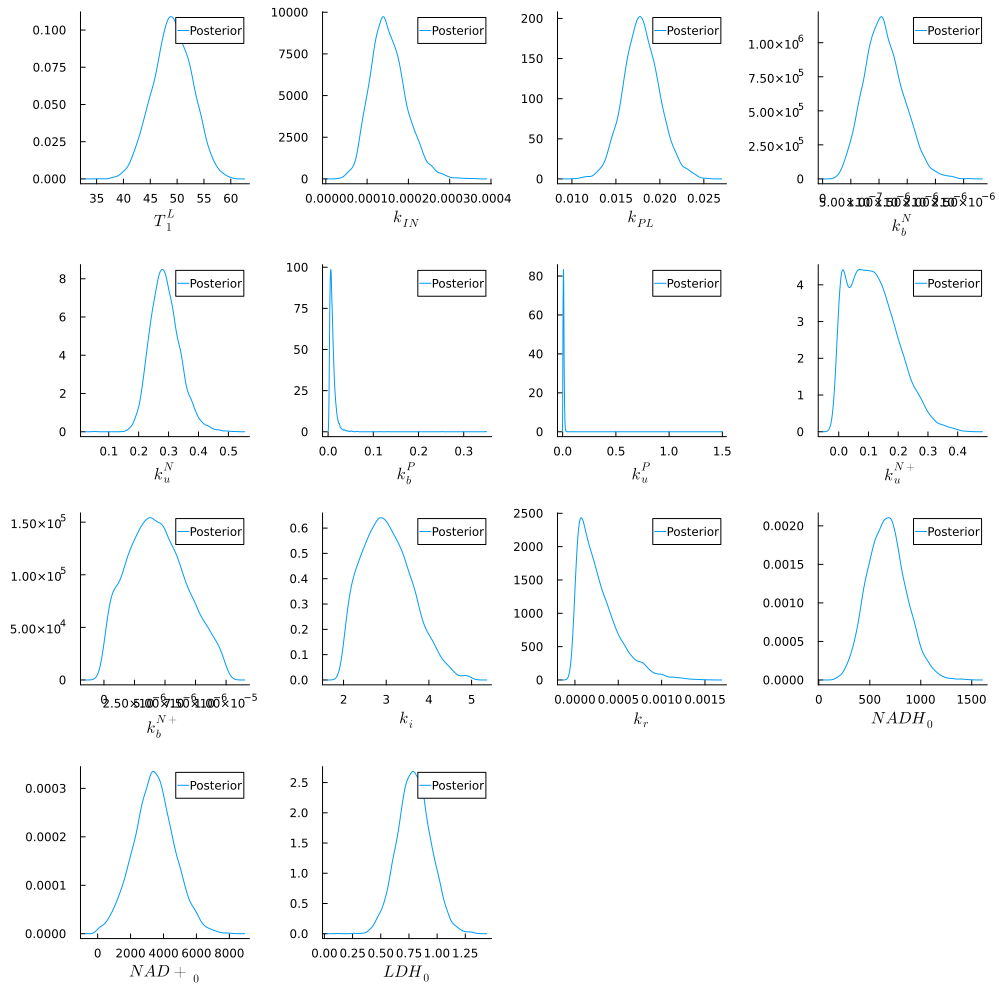

In [80]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"];

indss=vcat(1, 3:12, 15:17)
prisDis = vcat(priorTheta, priotY0)

pltsPost = Array{Any}(undef, length(indss))

for i in 1:length(indss)

    # [poster[:,11] .> 2]
    pltsPost[i] = plot(kde(poster[:,indss[i]][poster[:,11] .> 2]), label = "Posterior", xlabel = namess[i])

end

plot(pltsPost..., size=(1000,1000), grid = false)

In [65]:
using CairoMakie
using PairPlots
using DataFrames

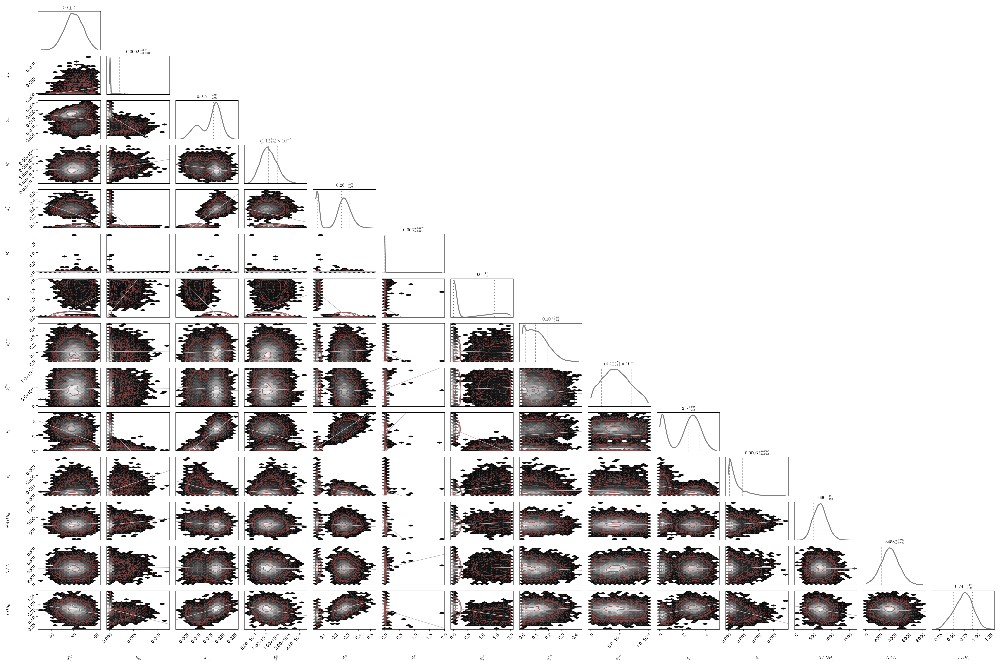

In [66]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,15:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

# save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

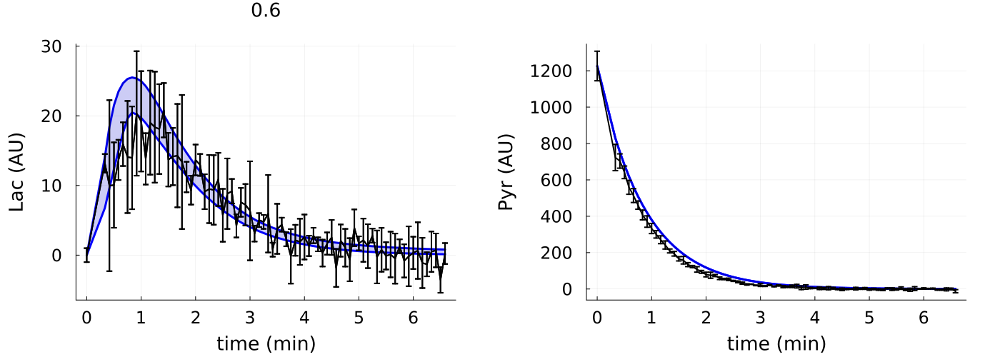

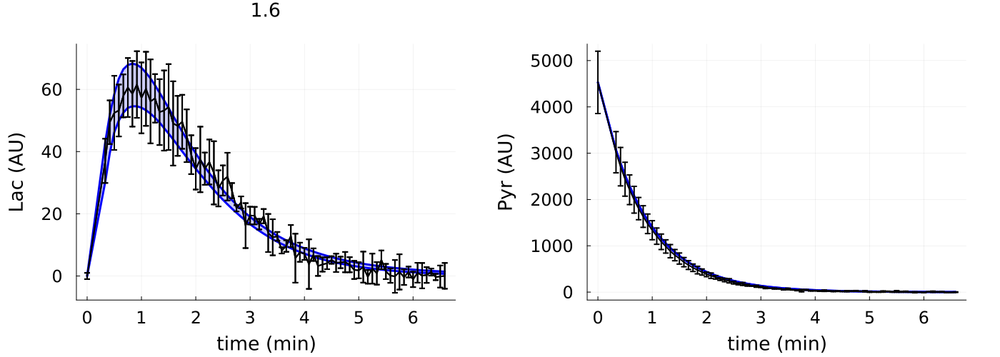

In [62]:
simPriorPredictAll(2000, dat, poster[:,1:14], poster[:,15:end], conce)